# Video 8: Spatial neighborhood analysis

Notes for this notebook.

This notebook generates the visuals for the eighth video in the Multimodal Spatial Biology series. In the last video, we saw five clusters that each looked spatially organized when plotted on their own. Looking is not measuring. Here we turn that visual impression into an actual statistic, similar in spirit to the Ripley's K style spatial statistics from the earlier spatial pathology mini series on this channel, and ask whether cells of the same type genuinely sit closer together than random chance would predict.

This notebook reuses the cluster assignments saved at the end of the Video 7 notebook. All output images are saved into outputs/video8.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


In [2]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video8")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


Output folder ready at: C:\Users\m6sbhatt\Documents\Personal\python_projects\unumlocalia\outputs\video8


## Load the clustered table

We reuse the five Leiden clusters from Video 7, saved at the end of that notebook.


In [3]:
df = pd.read_csv("outputs/video7/core01_hcc_clusters.csv")
print("Table shape:", df.shape)
print(df["leiden_cluster"].value_counts())


Table shape: (8283, 5025)
leiden_cluster
0    2062
1    2043
2    1791
3    1544
4     843
Name: count, dtype: int64


## The question, stated precisely

For each cell, we look at its ten nearest neighbors in physical space, and ask what fraction of them belong to the same cluster as the cell itself. If a cluster is spatially organized, cells of that type should have neighbors of the same type far more often than you would expect by chance. If a cluster were scattered randomly through the tissue, that fraction would simply reflect how common that cluster is overall, nothing more.

To know what chance actually looks like here, we shuffle the cluster labels across the same cell positions many times, and recompute the same fraction each time. That gives us a null distribution, what the same type neighbor fraction would look like if spatial organization did not exist at all, which we then compare our real, observed result against.


In [4]:
from sklearn.neighbors import NearestNeighbors

coords = df[["centroid_x", "centroid_y"]].values
labels = df["leiden_cluster"].values

k = 10  # number of nearest neighbors to check

nbrs = NearestNeighbors(n_neighbors=k + 1).fit(coords)
_, neighbor_idx = nbrs.kneighbors(coords)
neighbor_idx = neighbor_idx[:, 1:]  # drop each cell itself from its own neighbor list


def same_type_fraction(labels, neighbor_idx):
    neighbor_labels = labels[neighbor_idx]
    same = (neighbor_labels == labels[:, None])
    return same.mean(axis=1)


observed_fraction = same_type_fraction(labels, neighbor_idx)
observed_by_cluster = pd.Series(observed_fraction).groupby(labels).mean().sort_index()
print("Observed same type neighbor fraction, by cluster:")
print(observed_by_cluster)


Observed same type neighbor fraction, by cluster:
0    0.464597
1    0.596672
2    0.477554
3    0.448899
4    0.339858
dtype: float64


In [5]:
n_permutations = 200
rng = np.random.default_rng(0)
cluster_ids = sorted(set(labels))
null_fractions = np.zeros((n_permutations, len(cluster_ids)))

for i in range(n_permutations):
    shuffled = rng.permutation(labels)
    frac = same_type_fraction(shuffled, neighbor_idx)
    null_fractions[i] = pd.Series(frac).groupby(shuffled).mean().sort_index().values

null_mean = null_fractions.mean(axis=0)
null_std = null_fractions.std(axis=0)

results = pd.DataFrame({
    "cluster": cluster_ids,
    "observed_fraction": observed_by_cluster.values,
    "random_expected_fraction": null_mean,
    "z_score": (observed_by_cluster.values - null_mean) / null_std,
})
results["enrichment_ratio"] = results["observed_fraction"] / results["random_expected_fraction"]
print(results.round(3))


   cluster  observed_fraction  random_expected_fraction  z_score  \
0        0              0.465                     0.249   54.653   
1        1              0.597                     0.247   91.941   
2        2              0.478                     0.216   64.197   
3        3              0.449                     0.186   65.144   
4        4              0.340                     0.101   52.396   

   enrichment_ratio  
0             1.863  
1             2.420  
2             2.208  
3             2.407  
4             3.351  


## Reading the result carefully

Every one of the five clusters comes back with a large, positive z-score, none of this spatial organization is random, all five populations sit together in space far more than chance alone would produce.

The z-score itself needs a caveat before we read too much into comparing clusters by it directly. A rarer cluster has a lower random expected fraction to begin with, so even a modest amount of real clustering can produce a very large z-score just because the baseline was already low. The enrichment ratio, observed divided by expected, is a fairer way to compare clusters of very different sizes against each other.

By that measure, the smallest cluster from the last video, the one defined by podoplanin, comes out with the highest enrichment ratio of all five, despite being the rarest population in the tissue. That is a meaningful result on its own. A small, previously unnoticed population turning out to be the most spatially concentrated of everything we found is more consistent with a real, tightly organized structure, such as a small vessel, than with scattered noise cells that happened to end up in the same cluster.


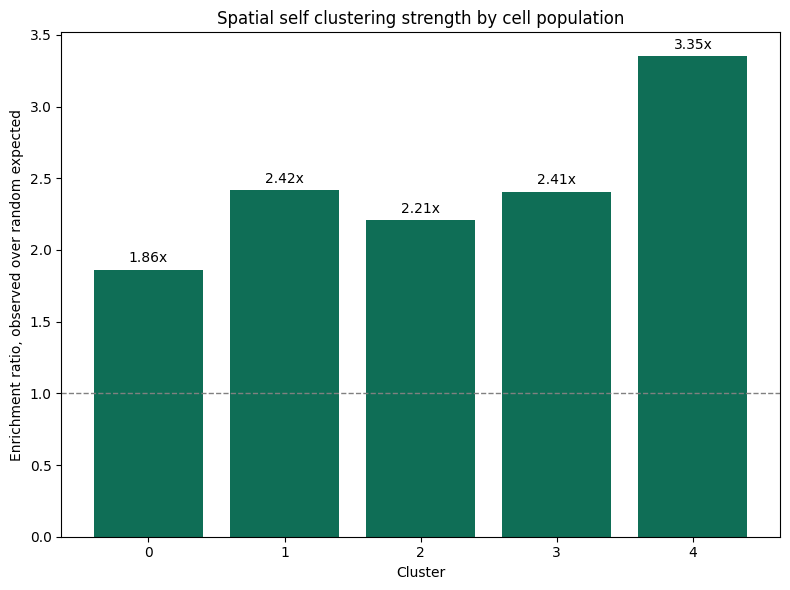

Saved slide_enrichment_ratio_by_cluster.png


In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(results["cluster"].astype(str), results["enrichment_ratio"], color="#0F6E56")
ax.set_xlabel("Cluster")
ax.set_ylabel("Enrichment ratio, observed over random expected")
ax.set_title("Spatial self clustering strength by cell population")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
for bar, value in zip(bars, results["enrichment_ratio"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.05, f"{value:.2f}x", ha="center")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_enrichment_ratio_by_cluster.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_enrichment_ratio_by_cluster.png")


## Summary

We turned a visual impression, these clusters look organized, into an actual statistic. All five cell populations from the last video show real, statistically significant spatial self clustering, confirmed against a proper random shuffle baseline rather than assumed from a plot. The smallest, most novel population from Video 7 also turned out to be the most spatially concentrated by this measure, additional evidence that it reflects genuine tissue biology rather than a clustering artifact.

Next episode, we go in a different direction and use something COMET's sixteen marker panel structurally cannot show us, gene level liver zonation, a pattern only visible through Xenium's much larger gene panel.
